Ukuran dataset awal: (7043, 21)
Ukuran data bersih : (7032, 20)

Distribusi Churn:
 Churn
No     5163
Yes    1869
Name: count, dtype: int64

X_train: (5625, 30) | X_test: (1407, 30)

=== LOGISTIC REGRESSION ===
Accuracy : 0.8045
ROC-AUC  : 0.8361
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407

=== RANDOM FOREST ===
Accuracy : 0.7882
ROC-AUC  : 0.8156
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



/tmp/ipykernel_612/158673366.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_imp.values, y=feat_imp.index, ax=axes[1], palette='viridis')


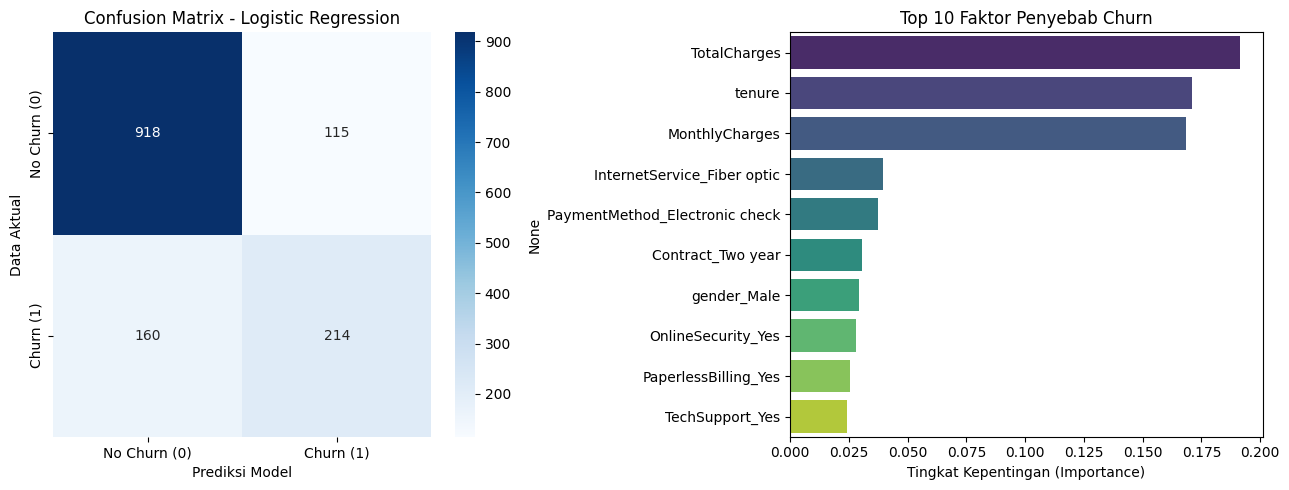


File model berhasil disimpan: churn_model.pkl, scaler.pkl, model_columns.pkl


In [12]:
# ==========================================
# 1. IMPORT LIBRARY & LOAD DATASET
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print("Ukuran dataset awal:", df.shape)

# ==========================================
# 2. DATA CLEANING
# ==========================================
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.dropna(subset=['TotalCharges']).copy()

if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

print("Ukuran data bersih :", df.shape)
print("\nDistribusi Churn:\n", df['Churn'].value_counts())

# ==========================================
# 3. PREPROCESSING (ENCODING, SPLIT & SCALING)
# ==========================================
y = df['Churn'].map({'No': 0, 'Yes': 1})
X = df.drop(columns=['Churn'])

X_encoded = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("\nX_train:", X_train.shape, "| X_test:", X_test.shape)

# ==========================================
# 4. TRAINING MODEL, EVALUASI & VISUALISASI
# ==========================================
# Model 1: Logistic Regression
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train, y_train)
y_pred_log = log_model.predict(X_test)
y_prob_log = log_model.predict_proba(X_test)[:, 1]

print("\n=== LOGISTIC REGRESSION ===")
print("Accuracy :", round(accuracy_score(y_test, y_pred_log), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_log), 4))
print(classification_report(y_test, y_pred_log))

# Model 2: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("=== RANDOM FOREST ===")
print("Accuracy :", round(accuracy_score(y_test, y_pred_rf), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_rf), 4))
print(classification_report(y_test, y_pred_rf))

# Visualisasi Confusion Matrix & Top 10 Faktor Penyebab Churn
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred_log)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['No Churn (0)', 'Churn (1)'],
            yticklabels=['No Churn (0)', 'Churn (1)'])
axes[0].set_title('Confusion Matrix - Logistic Regression')
axes[0].set_xlabel('Prediksi Model')
axes[0].set_ylabel('Data Aktual')

feat_imp = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)
sns.barplot(x=feat_imp.values, y=feat_imp.index, ax=axes[1], palette='viridis')
axes[1].set_title('Top 10 Faktor Penyebab Churn')
axes[1].set_xlabel('Tingkat Kepentingan (Importance)')

plt.tight_layout()
plt.show()

# ==========================================
# 5. SIMPAN MODEL UNTUK WEBSITE (OPSIONAL)
# ==========================================
joblib.dump(log_model, 'churn_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(list(X_train.columns), 'model_columns.pkl')
print("\nFile model berhasil disimpan: churn_model.pkl, scaler.pkl, model_columns.pkl")